<a href="https://colab.research.google.com/github/teju917/Machine_learning_lab2/blob/main/K_means_ckustering_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

          MALL CUSTOMER SEGMENTATION USING K-MEANS

1. ORIGINAL DATASET
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

2. DATASET SHAPE
Total Rows: 200
Total Columns: 5

3. COLUMN NAMES
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

4. DATA TYPES
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

5. MISSING VALUES
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
d

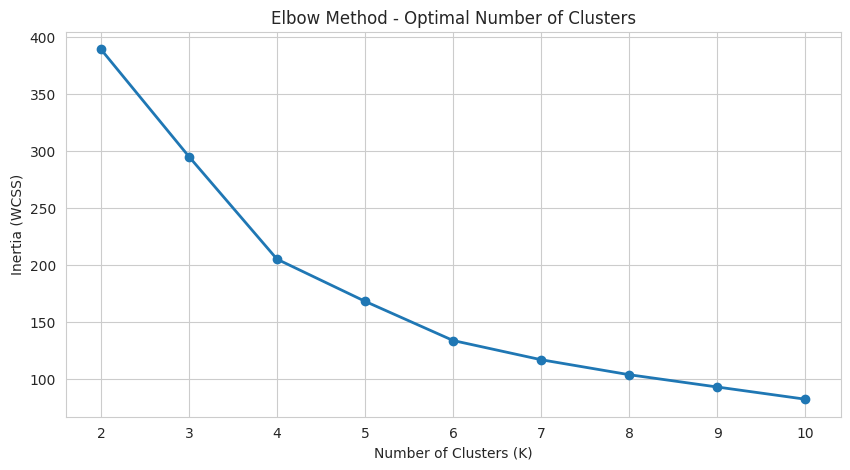


              SILHOUETTE SCORE ANALYSIS
K = 2 | Silhouette Score = 0.3355
K = 3 | Silhouette Score = 0.3578
K = 4 | Silhouette Score = 0.404
K = 5 | Silhouette Score = 0.4166
K = 6 | Silhouette Score = 0.4284
K = 7 | Silhouette Score = 0.4172
K = 8 | Silhouette Score = 0.4082
K = 9 | Silhouette Score = 0.4177
K = 10 | Silhouette Score = 0.4066

OPTIMAL K VALUE: 6
Highest Silhouette Score: 0.4284


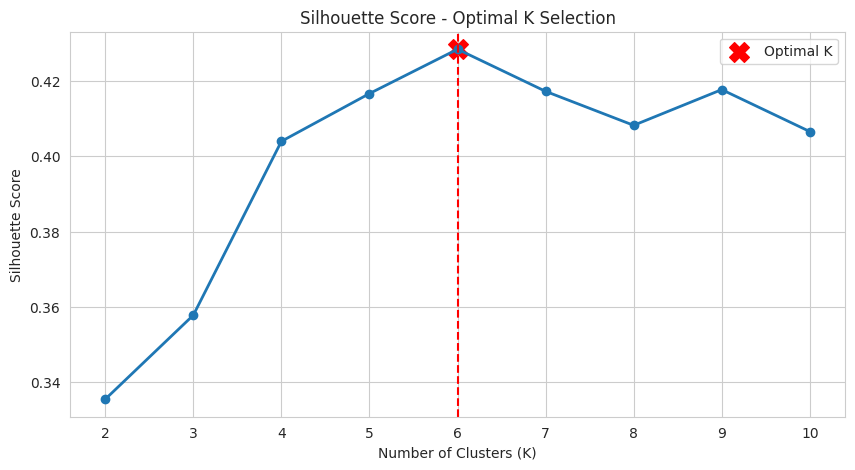


              K-MEANS CLUSTERING RESULTS

Optimal Number of Clusters: 6
Silhouette Score: 0.4284

CLUSTER COUNTS
Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

CLUSTERED DATASET
    CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0            1    Male   19                  15                      39   
1            2    Male   21                  15                      81   
2            3  Female   20                  16                       6   
3            4  Female   23                  16                      77   
4            5  Female   31                  17                      40   
5            6  Female   22                  17                      76   
6            7  Female   35                  18                       6   
7            8  Female   23                  18                      94   
8            9    Male   64                  19                       3   
9           10  Female   30        

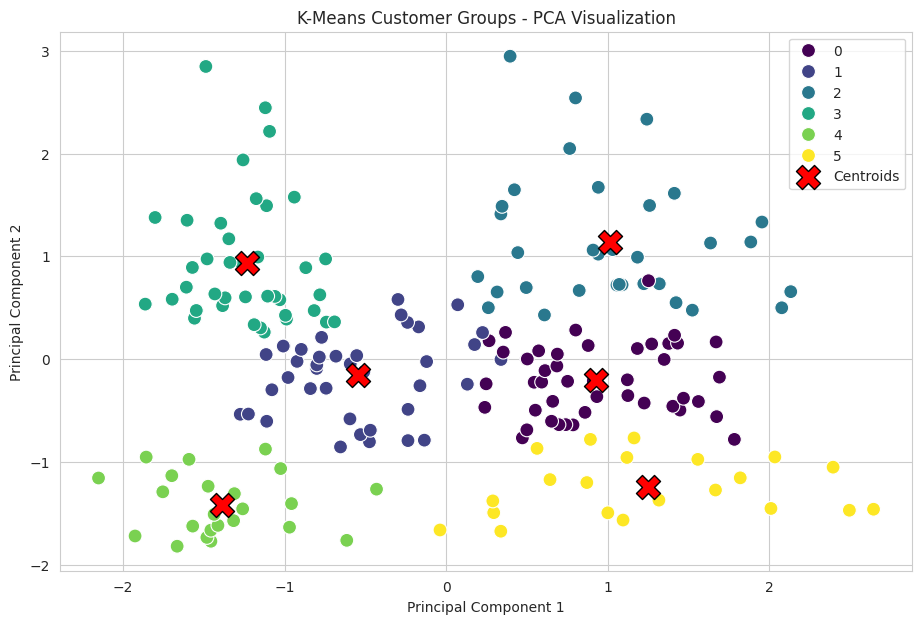

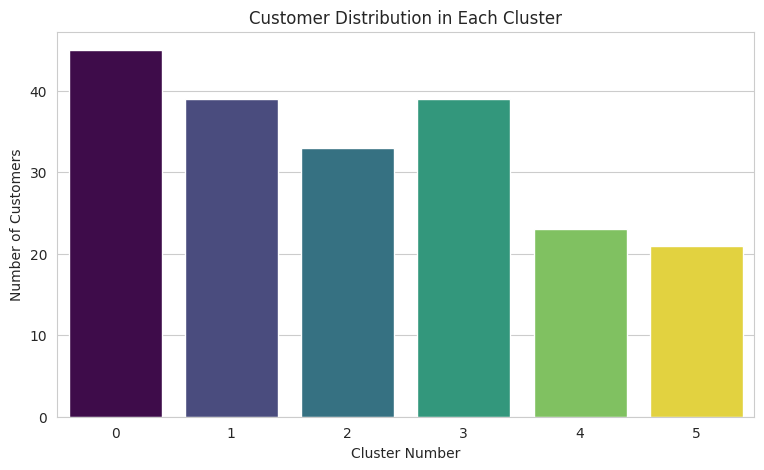


              CLUSTER-WISE ANALYSIS
               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        56.333333           54.266667               49.066667
1        26.794872           57.102564               48.128205
2        41.939394           88.939394               16.969697
3        32.692308           86.538462               82.128205
4        25.000000           25.260870               77.608696
5        45.523810           26.285714               19.380952

              FINAL CONCLUSION
Dataset: Mall Customer Segmentation
Total Customers: 200
Features Used: 3
Optimal K Value: 6
Final Silhouette Score: 0.4284

K-MEANS CLUSTERING COMPLETED SUCCESSFULLY!

Results saved as KMeans_Clustered_Results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# ============================================================
# K-MEANS CLUSTERING - MALL CUSTOMER SEGMENTATION
# Complete Program with Elbow Method, Silhouette Score and PCA
# ============================================================

!pip install -q pandas numpy matplotlib seaborn scikit-learn

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")

# ============================================================
# 2. LOAD THE DATASET AUTOMATICALLY
# ============================================================

url = "https://raw.githubusercontent.com/sharmaroshan/Clustering-of-Mall-Customers/master/Mall_Customers.csv"

df = pd.read_csv(url)

# Handle different dataset column names
df.columns = df.columns.str.strip()

if "Genre" in df.columns:
    df.rename(columns={"Genre": "Gender"}, inplace=True)

# ============================================================
# 3. FIRST OUTPUT - DATASET INFORMATION
# ============================================================

print("=" * 65)
print("          MALL CUSTOMER SEGMENTATION USING K-MEANS")
print("=" * 65)

print("\n1. ORIGINAL DATASET")
print(df.head())

print("\n2. DATASET SHAPE")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\n3. COLUMN NAMES")
print(df.columns.tolist())

print("\n4. DATA TYPES")
print(df.dtypes)

print("\n5. MISSING VALUES")
print(df.isnull().sum())

print("\n6. STATISTICAL SUMMARY")
print(df.describe())

# ============================================================
# 4. DATA PREPROCESSING
# ============================================================

print("\n" + "=" * 65)
print("              DATA PREPROCESSING")
print("=" * 65)

# Remove CustomerID and Gender
X = df.drop(columns=["CustomerID", "Gender"], errors="ignore")

X = X.select_dtypes(include=np.number)

X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

print("\nFeatures Selected:")
print(X.columns.tolist())

print("\nRecords Available:", len(X))

# Standardization
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nStandardization Completed Successfully!")

# ============================================================
# 5. ELBOW METHOD - FIND OPTIMAL K
# ============================================================

print("\n" + "=" * 65)
print("              ELBOW METHOD ANALYSIS")
print("=" * 65)

k_values = list(range(2, 11))

inertia = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

# Plot Elbow Graph
plt.figure(figsize=(10, 5))

plt.plot(
    k_values,
    inertia,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")

plt.title("Elbow Method - Optimal Number of Clusters")

plt.xticks(k_values)
plt.grid(True)
plt.show()

# ============================================================
# 6. SILHOUETTE SCORE - COMPARE K VALUES
# ============================================================

print("\n" + "=" * 65)
print("              SILHOUETTE SCORE ANALYSIS")
print("=" * 65)

silhouette_scores = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(
        "K =", k,
        "| Silhouette Score =", round(score, 4)
    )

# Select K with highest Silhouette Score
best_k = k_values[np.argmax(silhouette_scores)]

print("\nOPTIMAL K VALUE:", best_k)

print(
    "Highest Silhouette Score:",
    round(max(silhouette_scores), 4)
)

# Plot Silhouette Graph
plt.figure(figsize=(10, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o",
    linewidth=2
)

plt.scatter(
    best_k,
    max(silhouette_scores),
    color="red",
    marker="X",
    s=200,
    label="Optimal K"
)

plt.axvline(
    best_k,
    linestyle="--",
    color="red"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score - Optimal K Selection")

plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# 7. APPLY K-MEANS CLUSTERING
# ============================================================

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df_clustered = df.loc[X.index].copy()

df_clustered["Cluster"] = clusters

final_score = silhouette_score(
    X_scaled,
    clusters
)

# ============================================================
# 8. DISPLAY CLUSTERING RESULTS
# ============================================================

print("\n" + "=" * 65)
print("              K-MEANS CLUSTERING RESULTS")
print("=" * 65)

print("\nOptimal Number of Clusters:", best_k)

print("Silhouette Score:", round(final_score, 4))

print("\nCLUSTER COUNTS")

print(
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nCLUSTERED DATASET")

print(df_clustered.head(15))

# ============================================================
# 9. PCA DIMENSIONALITY REDUCTION
# ============================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

df_clustered["PCA1"] = X_pca[:, 0]
df_clustered["PCA2"] = X_pca[:, 1]

centers_pca = pca.transform(
    kmeans.cluster_centers_
)

print("\nPCA VARIANCE EXPLAINED:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

# ============================================================
# 10. PCA CLUSTER VISUALIZATION
# ============================================================

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_clustered,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    color="red",
    edgecolor="black",
    s=300,
    label="Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("K-Means Customer Groups - PCA Visualization")

plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# 11. CLUSTER DISTRIBUTION GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clustered,
    x="Cluster",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.xlabel("Cluster Number")
plt.ylabel("Number of Customers")

plt.title("Customer Distribution in Each Cluster")

plt.show()

# ============================================================
# 12. CLUSTER-WISE FEATURE ANALYSIS
# ============================================================

print("\n" + "=" * 65)
print("              CLUSTER-WISE ANALYSIS")
print("=" * 65)

print(
    df_clustered.groupby("Cluster")[X.columns].mean()
)

# ============================================================
# 13. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 65)
print("              FINAL CONCLUSION")
print("=" * 65)

print("Dataset: Mall Customer Segmentation")

print("Total Customers:", len(df_clustered))

print("Features Used:", X.shape[1])

print("Optimal K Value:", best_k)

print("Final Silhouette Score:", round(final_score, 4))

print("\nK-MEANS CLUSTERING COMPLETED SUCCESSFULLY!")

# ============================================================
# 14. SAVE CLUSTERED DATASET
# ============================================================

df_clustered.to_csv(
    "KMeans_Clustered_Results.csv",
    index=False
)

print("\nResults saved as KMeans_Clustered_Results.csv")

from google.colab import files

files.download("KMeans_Clustered_Results.csv")
